[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/13_boosting.ipynb)

# 13 · Boosting: Turning Weak Learners into a Strong One

**Part 1 — Classical supervised learning** · Notebook 13 of 27

In 1988, Michael Kearns and Leslie Valiant asked a question that sounds almost philosophical (ISYE 4600 W12): *can a set of weak learners create a single strong learner?* A "weak learner" is any classifier only slightly better than random guessing. The answer turned out to be yes, and the algorithm that proved it practical, **AdaBoost** (Freund & Schapire, 1997), won the Gödel Prize. The idea: train simple models **one after another**, each one focusing on the examples its predecessors got wrong, then combine them in a weighted vote. Notebook 12's random forest averaged many *independent, deep* trees to cut **variance**. Boosting adds *dependent, shallow* trees to cut **bias**. Its modern descendant, **gradient boosting** (XGBoost, LightGBM, CatBoost), is the method that wins most machine-learning competitions on tabular data today.

**What you'll learn**

1. Weak learners, decision stumps, and the boosting question
2. **AdaBoost** from scratch, worked round by round on a tiny example
3. Watching the boundary evolve from axis-aligned cuts to a complex shape
4. Where the formulas come from: AdaBoost minimizes the **exponential loss**
5. Why training error falls so fast (the $\prod_t Z_t$ bound)
6. Margins: why test error keeps improving after training error hits zero, and AdaBoost's weakness with noisy labels
7. **Gradient boosting**: fitting the residuals, i.e. gradient descent in function space
8. Shrinkage, depth, subsampling and early stopping
9. Gradient boosting for classification, and the modern libraries
10. Bagging vs. boosting, and how to choose

*Course map: ISYE 4600 W12 (Boosting Algorithms: weak learners, decision stumps, AdaBoost, exponential loss, gradient boosting) and HW4 Q4 (AdaBoost by hand); W13 (bagging vs. boosting).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingRegressor, GradientBoostingClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.datasets import make_moons, make_hastie_10_2, load_breast_cancer
import time
print("Ready ✓")

Setup complete ✓


Ready ✓


---
## 1. Weak learners and decision stumps

The classic weak learner is a **decision stump**: a depth-1 tree, "a one-question exam" (ISYE W12). It looks at a **single** feature $j$ and a threshold $b$:

$$h(x) = s\cdot\text{sign}(x_j - b), \qquad s \in \{+1, -1\}$$

A stump alone is a poor classifier: one axis-aligned cut. Boosting's claim is that a weighted vote of many stumps,

$$H(x) = \text{sign}\Big(\sum_{t=1}^T \alpha_t h_t(x)\Big)$$

can be as accurate as anything. Two questions remain, and AdaBoost answers both (ISYE W12): **how to choose each new stump** (train it on reweighted data that emphasizes past mistakes), and **how much to trust it** (its vote weight $\alpha_t$, larger for more accurate stumps).

Since AdaBoost reweights the data, the stump must handle **weighted** examples: it minimizes the weighted error $\epsilon = \sum_i D(i)\,\mathbb{1}[h(x^i) \ne y^i]$, where the weights $D(i)$ sum to 1. A fast exhaustive search, using the same sort-and-cumulative-sum trick as notebook 12's trees:

In [2]:
def fit_stump(X, y, D):
    """Best decision stump under example weights D (sum 1). y ∈ {−1, +1}. Returns (error, feature, threshold, sign)."""
    best = (np.inf, 0, 0.0, 1)
    for j in range(X.shape[1]):
        order = np.argsort(X[:, j]); xs, ys, ds = X[order, j], y[order], D[order]
        # predicting +1 to the RIGHT of the cut: errors = weight of +1's on the left + weight of −1's on the right
        left_pos = np.r_[0, np.cumsum(ds * (ys == 1))]; right_neg = np.r_[np.cumsum((ds * (ys == -1))[::-1])[::-1], 0]
        err_plus = left_pos + right_neg                          # cut after k sorted points, k = 0..m
        for err_k, s in [(err_plus, 1), (1 - err_plus, -1)]:     # flipping the sign flips which points are wrong
            k = int(np.argmin(err_k))
            thr = xs[0] - 1 if k == 0 else (xs[-1] + 1 if k == len(xs) else (xs[k - 1] + xs[k]) / 2)
            if err_k[k] < best[0]: best = (err_k[k], j, thr, s)
    return best

stump_predict = lambda X, j, thr, s: s * np.where(X[:, j] > thr, 1, -1)

---
## 2. AdaBoost, worked round by round

The algorithm, exactly as in ISYE 4600 (W12):

> **Input:** $(x^i, y^i)$, $y^i \in \{-1, +1\}$, $i = 1..m$; number of rounds $T$.
> **Initialize:** $D_1(i) = 1/m$.
> **For** $t = 1, \dots, T$:
> 1. Train a weak learner $h_t$ on the weighted data $D_t$.
> 2. Its weighted error: $\epsilon_t = \sum_i D_t(i)\,\mathbb{1}[y^i \ne h_t(x^i)]$.
> 3. Its vote weight: $\alpha_t = \frac12\ln\dfrac{1 - \epsilon_t}{\epsilon_t}$.
> 4. Reweight: $D_{t+1}(i) = \dfrac{D_t(i)\,e^{-\alpha_t y^i h_t(x^i)}}{Z_t}$, i.e. multiply by $e^{-\alpha_t}$ if correct, $e^{+\alpha_t}$ if wrong, then renormalize ($Z_t$ = the sum).
>
> **Output:** $H(x) = \text{sign}\big(\sum_t \alpha_t h_t(x)\big)$.

Notice: $\alpha_t > 0$ exactly when $\epsilon_t < 0.5$ (better than random), and $\alpha_t \to \infty$ as $\epsilon_t \to 0$. Misclassified points get **heavier**, so the next stump is forced to pay attention to them.

Let's run three rounds on a tiny 10-point dataset, in the spirit of ISYE's toy example and HW4's AdaBoost table, and print every number:

In [3]:
X10 = np.array([[1, 5], [2, 2], [3, 8], [4, 4], [5, 7], [6, 1], [7, 6], [8, 3], [9, 9], [10, 5]], float)
y10 = np.array([1, 1, -1, 1, -1, -1, 1, -1, -1, 1])

def adaboost(X, y, T, record=False):
    m = len(y); D = np.full(m, 1 / m); stumps, alphas, Ds, Zs = [], [], [D.copy()], []
    for t in range(T):
        eps, j, thr, s = fit_stump(X, y, D)
        eps = np.clip(eps, 1e-12, 1 - 1e-12)
        alpha = 0.5 * np.log((1 - eps) / eps)
        h = stump_predict(X, j, thr, s)
        w = D * np.exp(-alpha * y * h); Z = w.sum(); D = w / Z
        stumps.append((j, thr, s)); alphas.append(alpha); Zs.append(Z); Ds.append(D.copy())
    return stumps, np.array(alphas), Ds, np.array(Zs)

def ada_score(X, stumps, alphas, upto=None):
    return sum(a * stump_predict(X, *st) for st, a in list(zip(stumps, alphas))[:upto])

stumps10, alphas10, Ds10, Zs10 = adaboost(X10, y10, 3)
tab = pd.DataFrame({f"D{t+1}(i)": Ds10[t] for t in range(4)}, index=[f"point {i+1} (y={y10[i]:+d})" for i in range(10)]).round(3)
for t in range(3):
    j, thr, s = stumps10[t]; h = stump_predict(X10, j, thr, s)
    print(f"round {t+1}: stump 'x{j+1} {'>' if s == 1 else '≤'} {thr:.1f} → +1'   ε = {np.sum(Ds10[t] * (h != y10)):.3f}   "
          f"α = ½ ln((1−ε)/ε) = {alphas10[t]:.3f}   Z = {Zs10[t]:.3f}   wrong on points {(np.where(h != y10)[0] + 1).tolist()}")
tab

round 1: stump 'x2 ≤ 6.5 → +1'   ε = 0.200   α = ½ ln((1−ε)/ε) = 0.693   Z = 0.800   wrong on points [6, 8]
round 2: stump 'x1 ≤ 2.5 → +1'   ε = 0.187   α = ½ ln((1−ε)/ε) = 0.733   Z = 0.781   wrong on points [4, 7, 10]
round 3: stump 'x2 > 3.5 → +1'   ε = 0.154   α = ½ ln((1−ε)/ε) = 0.852   Z = 0.722   wrong on points [2, 3, 5, 9]


,D1(i),D2(i),D3(i),D4(i)
point 1 (y=+1),0.1,0.062,0.038,0.023
point 2 (y=+1),0.1,0.062,0.038,0.125
point 3 (y=-1),0.1,0.062,0.038,0.125
point 4 (y=+1),0.1,0.062,0.167,0.098
point 5 (y=-1),0.1,0.062,0.038,0.125
point 6 (y=-1),0.1,0.250,0.154,0.091
point 7 (y=+1),0.1,0.062,0.167,0.098
point 8 (y=-1),0.1,0.250,0.154,0.091
point 9 (y=-1),0.1,0.062,0.038,0.125
point 10 (y=+1),0.1,0.062,0.167,0.098


Follow a misclassified point across the columns: its weight jumps after the round it's missed, so the next stump would rather get *it* right than several easy points. Here's the same thing in pictures (circle size ∝ weight):

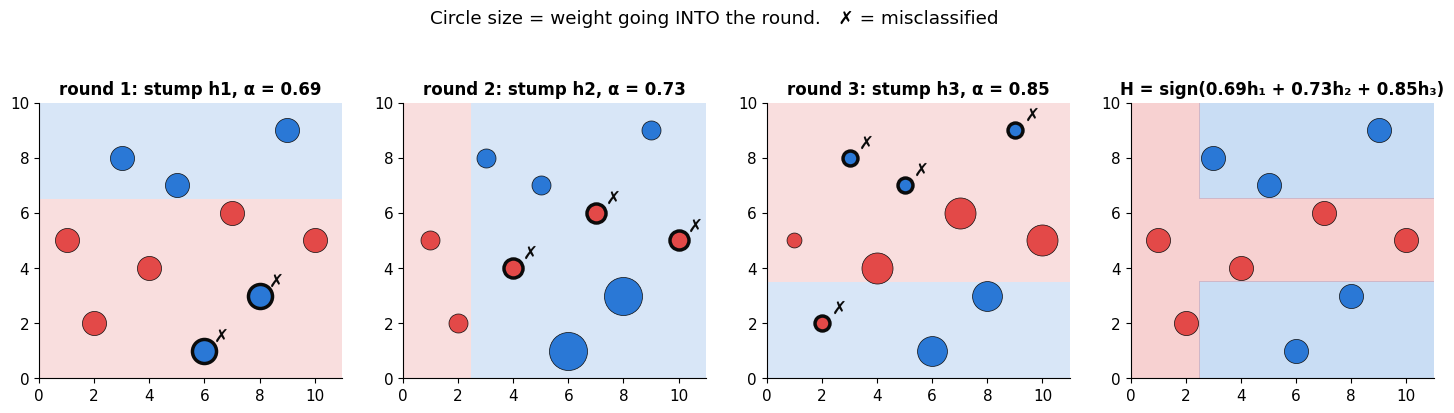

training error of the 3-stump ensemble: 0%  (each single stump: 20%, 30%, 40%)


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
g1, g2 = np.meshgrid(np.linspace(0, 11, 300), np.linspace(0, 10, 300)); G = np.column_stack([g1.ravel(), g2.ravel()])
for t in range(4):
    ax = axes[t]
    if t < 3:
        j, thr, s = stumps10[t]
        F = stump_predict(G, j, thr, s).reshape(g1.shape)
        ax.contourf(g1, g2, F, levels=[-2, 0, 2], colors=[C["blue"], C["red"]], alpha=0.18)
        ax.set_title(f"round {t+1}: stump h{t+1}, α = {alphas10[t]:.2f}")
        wts = Ds10[t]
    else:
        F = np.sign(ada_score(G, stumps10, alphas10)).reshape(g1.shape)
        ax.contourf(g1, g2, F, levels=[-2, 0, 2], colors=[C["blue"], C["red"]], alpha=0.25)
        ax.set_title(f"H = sign({alphas10[0]:.2f}h₁ + {alphas10[1]:.2f}h₂ + {alphas10[2]:.2f}h₃)")
        wts = np.full(10, 0.1)
    pred = stump_predict(X10, *stumps10[t]) if t < 3 else np.sign(ada_score(X10, stumps10, alphas10))
    for i in range(10):
        ax.scatter(*X10[i], s=3000 * wts[i], color=C["red"] if y10[i] == 1 else C["blue"], edgecolor=C["ink"], lw=2.5 if pred[i] != y10[i] else 0.5, zorder=3)
        if pred[i] != y10[i]: ax.text(X10[i, 0] + 0.35, X10[i, 1] + 0.35, "✗", fontsize=13, color=C["ink"])
    ax.set(xlim=(0, 11), ylim=(0, 10), aspect="equal"); ax.grid(False)
fig.suptitle("Circle size = weight going INTO the round.   ✗ = misclassified", y=1.02); plt.show()
print(f"training error of the 3-stump ensemble: {np.mean(np.sign(ada_score(X10, stumps10, alphas10)) != y10):.0%}  (each single stump: "
      f"{', '.join(f'{np.mean(stump_predict(X10, *st) != y10):.0%}' for st in stumps10)})")

The best single stump gets 8 of 10 points right; the weighted vote of three stumps gets all 10 right, better than any of its members. The combined boundary (right) is a staircase, already more complex than any one stump can draw.

> 🤔 **Question: What if a weak learner does worse than random ($\epsilon_t > 0.5$)?**
>
> Then $\alpha_t < 0$: AdaBoost flips its vote, which turns it into a better-than-random learner. In practice the stump search already chooses the better of each threshold's two orientations, so $\epsilon_t \le 0.5$ automatically. If $\epsilon_t = 0.5$ exactly, the learner carries no information, $\alpha_t = 0$, and boosting stalls.

---
## 3. Watching the boundary evolve

ISYE W12: "Over multiple iterations, the decision boundary evolves from simple vertical/horizontal splits to a nonlinear boundary that fits complex data." Here it is on the moons, over 300 rounds. The point sizes show the current weights: watch them concentrate on the hard points along the boundary.

In [5]:
Xm, ym = make_moons(300, noise=0.25, random_state=3); ym = 2 * ym - 1
stM, alM, DsM, ZsM = adaboost(Xm, ym, 300)
h1, h2 = np.meshgrid(np.linspace(-1.8, 2.8, 180), np.linspace(-1.3, 1.8, 130)); GH = np.column_stack([h1.ravel(), h2.ravel()])
stump_preds = np.array([stump_predict(GH, *st) for st in stM])                # precompute every stump on the grid
cum = np.cumsum(alM[:, None] * stump_preds, axis=0)

fig, ax = plt.subplots(figsize=(8, 5.2), dpi=72)
def frame(t):
    ax.clear()
    F = cum[t].reshape(h1.shape) / alM[:t + 1].sum()
    ax.contourf(h1, h2, F, levels=np.linspace(-1, 1, 21), cmap="RdBu_r", alpha=0.55)
    ax.contour(h1, h2, F, levels=[0], colors=C["ink"], linewidths=1.8)
    w = DsM[t + 1]; sz = 3 + 4000 * w
    ax.scatter(*Xm[ym == -1].T, s=sz[ym == -1], color=C["blue"], edgecolor="white", linewidth=0.3)
    ax.scatter(*Xm[ym == 1].T, s=sz[ym == 1], color=C["red"], edgecolor="white", linewidth=0.3)
    acc = np.mean(np.sign(ada_score(Xm, stM, alM, t + 1)) == ym)
    ax.set(xlim=(-1.8, 2.8), ylim=(-1.3, 1.8), title=f"{t + 1} stump{'s' if t else ''}:  training accuracy {acc:.0%}"); ax.grid(False)
    return []
show_anim(animation.FuncAnimation(fig, frame, frames=[0, 1, 2, 4, 7, 11, 17, 25, 40, 60, 90, 130, 180, 240, 299], interval=450))

---
## 4. Where the formulas come from: minimizing the exponential loss

AdaBoost looks like a clever heuristic, but ISYE 4600 (W12) shows it's an optimizer in disguise. Write the ensemble's score as $f(x) = \sum_t \alpha_t h_t(x)$, so the classifier is $\text{sign}(f)$ and $y f(x)$ is the **margin** (positive = correct). AdaBoost greedily minimizes the **exponential loss**

$$L(f) = \frac1m\sum_{i=1}^m e^{-y^i f(x^i)}$$

a smooth, convex upper bound on the 0/1 loss (notebook 08 compared it with the other surrogates).

**Adding one term.** Suppose we've built $f_{t-1}$ and add $\alpha h$. Then

$$L = \frac1m\sum_i e^{-y^i f_{t-1}(x^i)}\,e^{-\alpha y^i h(x^i)} \;\propto\; \sum_i D_t(i)\,e^{-\alpha y^i h(x^i)}$$

where $D_t(i) \propto e^{-y^i f_{t-1}(x^i)}$. **That's where the weights come from**: they're the current exponential loss of each example. Badly classified points (large negative margin) have huge loss, hence huge weight. Unrolling the update rule confirms $D_{t+1}(i) = e^{-y^i f_t(x^i)} / (m\prod_{s\le t} Z_s)$.

**Choosing $h$.** Split the sum into correct ($y h = +1$) and wrong ($y h = -1$) examples: $\sum_i D_t(i)e^{-\alpha y^ih} = (1 - \epsilon)e^{-\alpha} + \epsilon\,e^{\alpha}$. For any $\alpha > 0$, this is smallest when the weighted error $\epsilon$ is smallest. So: **fit the weak learner that minimizes weighted error.** That's step 1.

**Choosing $\alpha$.** Differentiate and set to zero (ISYE W12):

$$-(1 - \epsilon)e^{-\alpha} + \epsilon\,e^{\alpha} = 0 \;\;\Longrightarrow\;\; e^{2\alpha} = \frac{1 - \epsilon}{\epsilon} \;\;\Longrightarrow\;\; \alpha = \frac12\ln\frac{1-\epsilon}{\epsilon}$$

That's step 3. Every piece of AdaBoost falls out of greedily minimizing one loss function, one term at a time. This view, **forward stagewise additive modeling** (Friedman, Hastie & Tibshirani, 2000), is what generalizes to gradient boosting in section 7.

Check numerically that the closed-form $\alpha$ really is the minimizer of the round's loss:

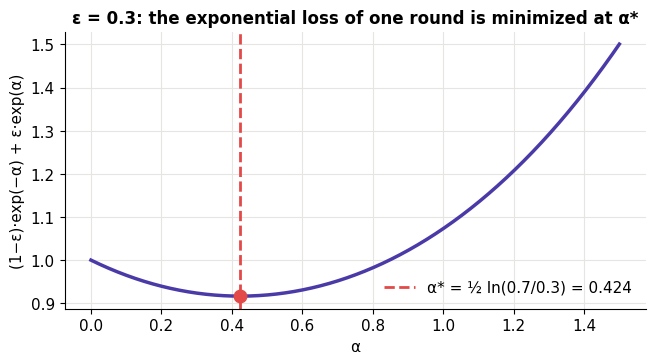

In [6]:
eps_ = 0.3
alphas_grid = np.linspace(0, 1.5, 300)
loss_grid = (1 - eps_) * np.exp(-alphas_grid) + eps_ * np.exp(alphas_grid)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(alphas_grid, loss_grid, color=C["violet"], lw=2.5)
a_star = 0.5 * np.log((1 - eps_) / eps_)
ax.axvline(a_star, color=C["red"], ls="--", label=f"α* = ½ ln(0.7/0.3) = {a_star:.3f}")
ax.plot(a_star, 2 * np.sqrt(eps_ * (1 - eps_)), "o", color=C["red"], ms=9)
ax.set(xlabel="α", ylabel="(1−ε)·exp(−α) + ε·exp(α)", title="ε = 0.3: the exponential loss of one round is minimized at α*"); ax.legend()
plt.show()

(With $\epsilon = 0.3$ this gives $\alpha = 0.42$, the value in ISYE's worked example.)

---
## 5. Why training error falls so fast

Plug $\alpha_t$ back in: the normalizer becomes $Z_t = 2\sqrt{\epsilon_t(1 - \epsilon_t)}$, which is **less than 1** whenever $\epsilon_t < 0.5$. Because the 0/1 loss is bounded by the exponential loss, the training error of the final classifier is bounded by the product of the $Z$'s:

$$\text{training error}(H) \;\le\; \frac1m\sum_i e^{-y^i f(x^i)} \;=\; \prod_{t=1}^T Z_t \;=\; \prod_t \sqrt{1 - 4\gamma_t^2} \;\le\; \exp\Big(-2\sum_t\gamma_t^2\Big)$$

where $\gamma_t = 0.5 - \epsilon_t$ is how much better than random each learner is. If every weak learner is at least a little better than random ($\gamma_t \ge \gamma > 0$), training error drops **exponentially fast** in the number of rounds. That's the formal answer to Kearns and Valiant: weak learning implies strong learning.

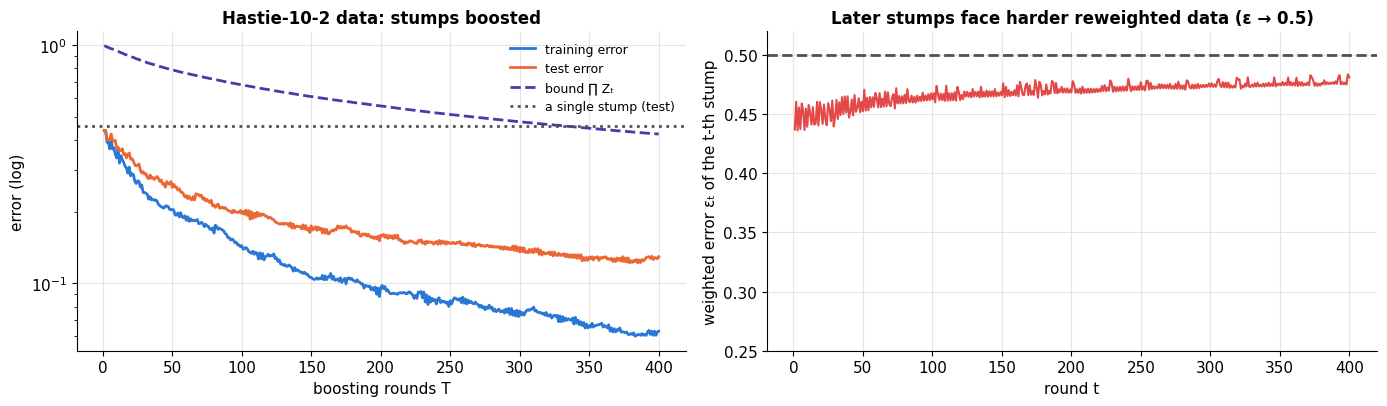

single stump test error: 0.458;  400 boosted stumps: 0.130


In [7]:
Xh, yh = make_hastie_10_2(n_samples=4000, random_state=1)        # a classic boosting benchmark: 10 features, nonlinear boundary
trh, teh = np.arange(2000), np.arange(2000, 4000)
stH, alH, DsH, ZsH = adaboost(Xh[trh], yh[trh], 400)
scores_tr = np.cumsum(alH[:, None] * np.array([stump_predict(Xh[trh], *s) for s in stH]), axis=0)
scores_te = np.cumsum(alH[:, None] * np.array([stump_predict(Xh[teh], *s) for s in stH]), axis=0)
tr_err = np.mean(np.sign(scores_tr) != yh[trh][None, :], axis=1); te_err = np.mean(np.sign(scores_te) != yh[teh][None, :], axis=1)
eps_t = 0.5 - 0.5 * np.sqrt(1 - ZsH ** 2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
T_ = np.arange(1, 401)
ax1.semilogy(T_, tr_err + 1e-4, color=C["blue"], lw=2, label="training error")
ax1.semilogy(T_, te_err, color=C["orange"], lw=2, label="test error")
ax1.semilogy(T_, np.cumprod(ZsH), color=C["violet"], ls="--", lw=2, label="bound ∏ Zₜ")
ax1.axhline(1 - DecisionTreeClassifier(max_depth=1).fit(Xh[trh], yh[trh]).score(Xh[teh], yh[teh]), color=C["muted"], ls=":", label="a single stump (test)")
ax1.set(xlabel="boosting rounds T", ylabel="error (log)", title="Hastie-10-2 data: stumps boosted"); ax1.legend(fontsize=9)
ax2.plot(T_, eps_t, color=C["red"], lw=1.5)
ax2.axhline(0.5, color=C["muted"], ls="--"); ax2.set(xlabel="round t", ylabel="weighted error εₜ of the t-th stump", ylim=(0.25, 0.52),
                                                   title="Later stumps face harder reweighted data (ε → 0.5)")
fig.tight_layout(); plt.show()
print(f"single stump test error: {1 - DecisionTreeClassifier(max_depth=1).fit(Xh[trh], yh[trh]).score(Xh[teh], yh[teh]):.3f};  "
      f"400 boosted stumps: {te_err[-1]:.3f}")

A single stump has ~46% test error on this problem, barely better than a coin. Four hundred of them, boosted, get about 13%. The bound $\prod Z_t$ (dashed) sits above the training error and falls exponentially, as promised. The right panel shows the price: each new stump faces a harder reweighted problem, so later $\epsilon_t$ creep toward 0.5 and each contributes less.

---
## 6. Margins, and AdaBoost's weakness with noisy labels

Stumps are too weak to fit the Hastie data perfectly, so the training error above never reaches zero. Give AdaBoost slightly stronger weak learners, depth-3 trees, and something surprising happens: training error hits **zero** after a couple of hundred rounds, yet the **test error keeps decreasing** afterward. A model that already classifies every training point correctly keeps getting *better* on new data? Notebook 06 would predict overfitting.

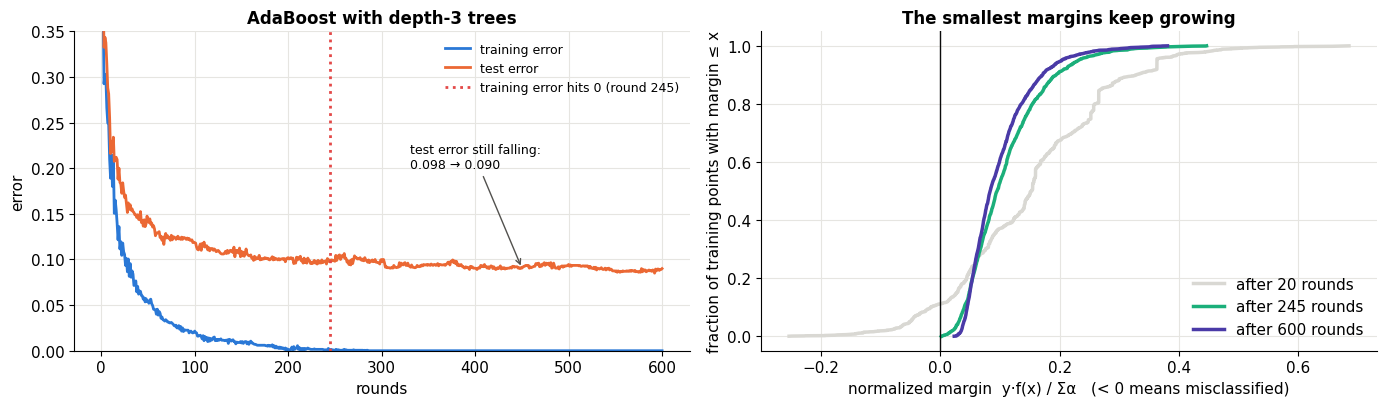

In [8]:
ab3 = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3), n_estimators=600, random_state=0).fit(Xh[trh], yh[trh])
tr3 = np.array([np.mean(p != yh[trh]) for p in ab3.staged_predict(Xh[trh])])
te3 = np.array([np.mean(p != yh[teh]) for p in ab3.staged_predict(Xh[teh])])
zero_at = int(np.argmax(tr3 == 0))
votes = np.array([e.predict(Xh[trh]) for e in ab3.estimators_]) * ab3.estimator_weights_[:, None]   # each tree's weighted ±1 vote
cum_votes = np.cumsum(votes, axis=0); cum_w = np.cumsum(ab3.estimator_weights_)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
R3 = np.arange(1, len(tr3) + 1)
ax1.plot(R3, tr3, color=C["blue"], lw=2, label="training error"); ax1.plot(R3, te3, color=C["orange"], lw=2, label="test error")
ax1.axvline(zero_at + 1, color=C["red"], ls=":", label=f"training error hits 0 (round {zero_at + 1})")
ax1.annotate(f"test error still falling:\n{te3[zero_at]:.3f} → {te3[-1]:.3f}", (450, te3[449]), xytext=(330, 0.2), fontsize=9, arrowprops=dict(arrowstyle="->", color=C["muted"]))
ax1.set(xlabel="rounds", ylabel="error", ylim=(0, 0.35), title="AdaBoost with depth-3 trees"); ax1.legend(fontsize=9)
for T_show, col in zip([20, zero_at + 1, 600], [C["light"], C["aqua"], C["violet"]]):
    mg = yh[trh] * cum_votes[T_show - 1] / cum_w[T_show - 1]
    ax2.plot(np.sort(mg), np.linspace(0, 1, len(mg)), color=col, lw=2.5, label=f"after {T_show} rounds")
ax2.axvline(0, color=C["ink"], lw=1)
ax2.set(xlabel="normalized margin  y·f(x) / Σα   (< 0 means misclassified)", ylabel="fraction of training points with margin ≤ x",
        title="The smallest margins keep growing"); ax2.legend()
fig.tight_layout(); plt.show()

The explanation is the **margin** (right panel). Normalize the score: $\text{margin}(x) = y\,f(x)/\sum_t\alpha_t \in [-1, 1]$. Once every margin is positive, the 0/1 training error can't improve, but the exponential loss still can: it keeps pushing the *smallest* margins upward, making the classifier more confident on its hardest correct points. Larger margins leave more room for error on new data, the same intuition as the SVM's widest street (notebook 11).

(Schapire et al., 1998, turned this into a generalization bound that depends on the margin distribution rather than the number of rounds. The effect is real but modest: here test error drops from about 9.8% to 9.0% after training error has already hit zero.)

**The flip side.** The exponential loss grows exponentially for negative margins. A **mislabeled** point can never be classified "correctly," so its weight keeps growing, and later learners spend more and more effort chasing it. Here's what happens when 15% of the training labels are flipped:

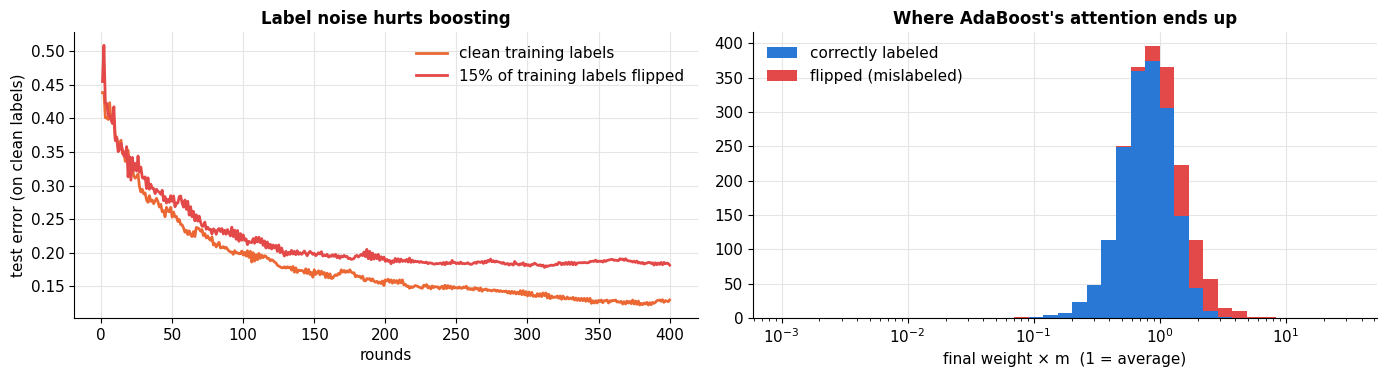

share of total weight on the 15% mislabeled points after 400 rounds: 28%


In [9]:
r_ = np.random.default_rng(0)
yh_noisy = yh[trh].copy(); flip = r_.random(len(trh)) < 0.15; yh_noisy[flip] *= -1
stN, alN, DsN, _ = adaboost(Xh[trh], yh_noisy, 400)
te_err_noisy = np.mean(np.sign(np.cumsum(alN[:, None] * np.array([stump_predict(Xh[teh], *s) for s in stN]), axis=0)) != yh[teh][None, :], axis=1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 3.9))
ax1.plot(T_, te_err, color=C["orange"], lw=2, label="clean training labels")
ax1.plot(T_, te_err_noisy, color=C["red"], lw=2, label="15% of training labels flipped")
ax1.set(xlabel="rounds", ylabel="test error (on clean labels)", title="Label noise hurts boosting"); ax1.legend()
ax2.hist([DsN[-1][~flip] * len(trh), DsN[-1][flip] * len(trh)], bins=np.logspace(-3, 1.5, 40), stacked=True, color=[C["blue"], C["red"]], label=["correctly labeled", "flipped (mislabeled)"])
ax2.set(xscale="log", xlabel="final weight × m  (1 = average)", title="Where AdaBoost's attention ends up"); ax2.legend()
fig.tight_layout(); plt.show()
print(f"share of total weight on the {flip.mean():.0%} mislabeled points after 400 rounds: {DsN[-1][flip].sum():.0%}")

By the end, the 15% of points with wrong labels hold roughly twice their fair share of the total weight, and the test error is clearly worse. With more rounds or more noise, it gets worse still. That's why variants with gentler losses exist (LogitBoost uses the logistic loss, which grows linearly instead of exponentially), and why gradient boosting with the log loss is the usual choice today.

---
## 7. Gradient boosting: fitting the residuals

Section 4 showed AdaBoost greedily minimizes one specific loss. **Gradient boosting** (Friedman, 2001) generalizes the idea to **any differentiable loss** (ISYE W12). Start with regression and squared loss, where the intuition is clearest:

1. Start with a constant: $f_0(x) = \bar y$.
2. Compute the **residuals** $r^i = y^i - f_{t-1}(x^i)$: what the current model still gets wrong.
3. Fit a small regression tree $h_t$ to the residuals.
4. Add it, scaled down by a **learning rate** $\nu$: $f_t = f_{t-1} + \nu\,h_t$.
5. Repeat.

Each tree learns to correct the mistakes of the ensemble so far. Why "gradient"? For squared loss $\frac12(y - f)^2$, the residual is exactly the **negative gradient** with respect to the prediction: $-\frac{\partial}{\partial f}\frac12(y - f)^2 = y - f$. So each round takes a gradient-descent step, but in **function space**: instead of nudging parameters (notebook 03), we nudge the function's value at every training point, and the tree is how we generalize that nudge to new points.

In [10]:
def gradient_boost_regression(x, y, n_rounds=100, lr=0.1, depth=2, x_eval=None):
    f0 = y.mean(); F = np.full(len(y), f0); trees, preds = [], []
    Fe = np.full(len(x_eval), f0) if x_eval is not None else None
    for t in range(n_rounds):
        r = y - F                                                     # residuals = negative gradient of squared loss
        tree = DecisionTreeRegressor(max_depth=depth).fit(x, r)
        F = F + lr * tree.predict(x); trees.append(tree)
        if x_eval is not None:
            Fe = Fe + lr * tree.predict(x_eval); preds.append((Fe.copy(), F.copy(), r, tree))
    return f0, trees, preds

r_ = np.random.default_rng(1)
xr = np.sort(r_.uniform(0, 10, 150)); yr = np.sin(xr) * 2 + 0.3 * xr + r_.normal(0, 0.4, 150)
xe = np.linspace(0, 10, 500)
f0, trees_r, preds_r = gradient_boost_regression(xr[:, None], yr, n_rounds=120, lr=0.3, depth=1, x_eval=xe[:, None])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.3), dpi=72)
def frame(t):
    ax1.clear(); ax2.clear()
    Fe, F, r, tree = preds_r[t]
    ax1.scatter(xr, yr, s=10, color=C["blue"], alpha=0.6)
    ax1.plot(xe, Fe, color=C["red"], lw=2.5)
    ax1.set(ylim=(-3, 6), title=f"ensemble after {t + 1} stump{'s' if t else ''}:  train MSE {np.mean((yr - F) ** 2):.3f}")
    ax2.scatter(xr, r, s=10, color=C["orange"])
    ax2.plot(xe, tree.predict(xe[:, None]), color=C["ink"], lw=2)
    ax2.axhline(0, color=C["muted"], lw=0.8)
    ax2.set(ylim=(-3.5, 3.5), title=f"round {t + 1}: residuals (orange) and the stump fit to them (black)")
    return []
fig.tight_layout()
show_anim(animation.FuncAnimation(fig, frame, frames=[0, 1, 2, 3, 5, 8, 12, 18, 25, 35, 50, 70, 95, 119], interval=450))

At first the residuals have obvious structure and each stump grabs a big chunk of it. As the ensemble improves, the residuals look more and more like noise, and each new stump changes less.

### Any loss, same recipe

For a general loss $\ell(y, f)$, replace "residual" with the **pseudo-residual** $r^i = -\partial\ell(y^i, f)/\partial f$ evaluated at the current prediction, fit a tree to those, and (optionally) pick the best step size for each leaf. Some useful losses:

| Loss | Pseudo-residual $-\partial\ell/\partial f$ | Good for |
|---|---|---|
| Squared $\frac12(y - f)^2$ | $y - f$ | standard regression |
| Absolute $\lvert y - f\rvert$ | $\text{sign}(y - f)$ | regression with outliers |
| Huber | $y - f$ if small, else clipped | best of both |
| Log loss (binary cross-entropy, $y\in\{0,1\}$, $f$ = log-odds) | $y - \sigma(f)$ | classification (notebook 08's gradient!) |
| Exponential $e^{-yf}$ | $y\,e^{-yf}$ | recovers AdaBoost |

---
## 8. Shrinkage, depth, subsampling and early stopping

Gradient boosting has more knobs than a random forest, and they interact:

- **Number of rounds $T$**: unlike random forests, boosting **can overfit** as $T$ grows, because each round reduces training error further.
- **Learning rate $\nu$** ("shrinkage"): smaller steps need more rounds but generalize better. A classic finding (Friedman, 2001): small $\nu$ (≤ 0.1) with many rounds almost always beats large $\nu$ with few.
- **Tree depth**: depth 1 (stumps) gives an additive model with no interactions; depth $d$ allows interactions among up to $d$ features. Typical values: 3–8.
- **Subsampling** ("stochastic gradient boosting"): fit each tree on a random fraction of the data, adding randomness that reduces variance, as in bagging.

🎚️ **Tune them on the 1-D regression problem.** Watch the test error curve: its minimum tells you when to stop.

In [11]:
xr_te = np.sort(r_.uniform(0, 10, 2000)); yr_te = np.sin(xr_te) * 2 + 0.3 * xr_te + r_.normal(0, 0.4, 2000)

def plot_gb(lr=0.1, depth=2, n_rounds=300, subsample=1.0):
    gb = GradientBoostingRegressor(learning_rate=lr, max_depth=depth, n_estimators=n_rounds, subsample=subsample, random_state=0).fit(xr[:, None], yr)
    tr_curve = [np.mean((yr - p) ** 2) for p in gb.staged_predict(xr[:, None])]
    te_curve = [np.mean((yr_te - p) ** 2) for p in gb.staged_predict(xr_te[:, None])]
    best = int(np.argmin(te_curve))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
    ax1.scatter(xr, yr, s=10, color=C["blue"], alpha=0.6)
    ax1.plot(xe, gb.predict(xe[:, None]), color=C["red"], lw=2.2, label=f"after {n_rounds} rounds")
    ax1.plot(xe, np.sin(xe) * 2 + 0.3 * xe, color=C["aqua"], lw=1.5, ls="--", label="truth")
    ax1.set(ylim=(-3, 6), title=f"ν = {lr}, depth {depth}, subsample {subsample}"); ax1.legend(loc="upper left", fontsize=9)
    ax2.plot(tr_curve, color=C["blue"], label="train MSE"); ax2.plot(te_curve, color=C["orange"], label="test MSE")
    ax2.axvline(best, color=C["red"], ls=":", label=f"best: {best + 1} rounds (test MSE {te_curve[best]:.3f})")
    ax2.axhline(0.16, color=C["muted"], ls="--", lw=1); ax2.text(n_rounds * 0.6, 0.17, "noise floor", fontsize=8)
    ax2.set(yscale="log", xlabel="round", ylim=(0.03, 5), title="Early stopping: stop where test error bottoms out"); ax2.legend(fontsize=9)
    fig.tight_layout(); plt.show()

interact(plot_gb, lr=widgets.SelectionSlider(options=[0.01, 0.03, 0.1, 0.3, 1.0], value=0.1, description="learning rate ν"),
         depth=IntSlider(value=2, min=1, max=6, description="tree depth"),
         n_rounds=IntSlider(value=300, min=20, max=1000, step=20, description="rounds"),
         subsample=FloatSlider(value=1.0, min=0.3, max=1.0, step=0.1, description="subsample"));

Try $\nu = 1.0$ with depth 4: the training error collapses within a few rounds and the test error turns up early (overfitting). With $\nu = 0.03$ the curves move slowly and the minimum is lower and wider. In practice, set a small learning rate, a generous maximum number of rounds, and use **early stopping** on a validation set (every modern library supports it).

---
## 9. Gradient boosting for classification, and the modern libraries

For binary classification, gradient boosting models the **log-odds** $f(x)$ and uses the log loss, so each round fits a tree to the pseudo-residuals $y^i - \sigma(f(x^i))$: "what the label is minus what the model currently predicts," exactly notebook 08's gradient. Here's a head-to-head on the Hastie benchmark from section 5, all with default-ish settings:

In [12]:
contenders = {
    "single tree (depth 6)": lambda: DecisionTreeClassifier(max_depth=6, random_state=0),
    "AdaBoost (400 stumps)": lambda: AdaBoostClassifier(n_estimators=400, random_state=0),
    "random forest (300 trees)": lambda: RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1),
    "gradient boosting (300, depth 3)": lambda: GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.1, random_state=0),
    "hist. gradient boosting (LightGBM-style)": lambda: HistGradientBoostingClassifier(max_iter=300, early_stopping=False, random_state=0),
}
rows = []
for name, mk in contenders.items():
    t0 = time.time(); mdl = mk().fit(Xh[trh], yh[trh]); dt = time.time() - t0
    rows.append(dict(model=name, test_error=1 - mdl.score(Xh[teh], yh[teh]), fit_seconds=dt))
pd.DataFrame(rows).set_index("model").round(3)

,test_error,fit_seconds
model,,
single tree (depth 6),0.344,0.013
AdaBoost (400 stumps),0.120,1.394
random forest (300 trees),0.147,1.157
"gradient boosting (300, depth 3)",0.115,1.772
hist. gradient boosting (LightGBM-style),0.107,0.534


On this problem every boosted ensemble beats the random forest (roughly 11–12% error vs. 15%), and all of them crush a single tree (34%). That's typical for problems where the true boundary is a smooth combination of many features: boosting builds it up additively, while each forest tree has to approximate it with axis-aligned boxes on its own.

The libraries that dominate practice add engineering on top of the same idea:

- **XGBoost** (Chen & Guestrin, 2016): uses the **second derivative** of the loss too (a Newton step in function space, notebook 08's Newton method again), explicit $\ell_1$/$\ell_2$ penalties on leaf values, sparsity-aware splits, and heavy parallelization.
- **LightGBM** (Microsoft, 2017): **histogram** binning of features (scikit-learn's `HistGradientBoostingClassifier` copies this) and leaf-wise tree growth; very fast on large data.
- **CatBoost** (Yandex, 2018): careful handling of categorical features and an "ordered" scheme that reduces a subtle target-leakage bias.

They're all preinstalled on Colab. If XGBoost is available, here it is on the same data:

In [13]:
try:
    import xgboost as xgb
    t0 = time.time()
    xg = xgb.XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.1, verbosity=0).fit(Xh[trh], (yh[trh] > 0).astype(int))
    print(f"XGBoost: test error {np.mean(xg.predict(Xh[teh]) != (yh[teh] > 0)):.3f}, fit in {time.time() - t0:.2f}s")
except ImportError:
    print("xgboost isn't installed here (it is on Colab: just run this cell there).")

xgboost isn't installed here (it is on Colab: just run this cell there).


> 🤔 **Question: If boosting wins on tabular data, why does deep learning dominate images and text?**
>
> Trees split on individual features with thresholds, which is perfect when each column has its own meaning (age, income, blood pressure) but terrible for raw pixels or characters, where meaning lives in patterns spread across many inputs and invariances (a cat shifted by 10 pixels is still a cat). Neural networks learn those representations (Part 3). On tabular data, well-tuned gradient boosting still matches or beats deep learning in most benchmarks (Grinsztajn et al., 2022).

---
## 10. Bagging vs. boosting

| | Bagging / random forests (notebook 12) | Boosting |
|---|---|---|
| Base learners | deep trees (low bias, high variance) | shallow trees / stumps (high bias, low variance) |
| Built | independently, in parallel | sequentially, each fixing the last |
| Combination | plain average / vote | weighted sum ($\alpha_t$ or learning rate) |
| Mainly reduces | **variance** | **bias** (and some variance) |
| Overfits as you add learners? | no | **yes**: needs early stopping |
| Sensitive to label noise? | robust | AdaBoost very; log-loss GB less so |
| Tuning effort | low | moderate (learning rate, depth, rounds) |
| Typical accuracy on tabular data | very good | often the best |

A practical recipe: start with a random forest (robust, nearly tuning-free baseline), then try gradient boosting with a small learning rate and early stopping. If boosting wins clearly, tune it.

---
## 11. Summary

- **Boosting** combines weak learners sequentially, each trained on data reweighted toward previous mistakes.
- **AdaBoost**: $\epsilon_t$ = weighted error, $\alpha_t = \frac12\ln\frac{1-\epsilon_t}{\epsilon_t}$, $D_{t+1}(i) \propto D_t(i)e^{-\alpha_ty^ih_t(x^i)}$, $H = \text{sign}\sum_t\alpha_th_t$.
- It's **greedy minimization of the exponential loss**; the weights are each point's current loss, and training error $\le \prod_t Z_t \le e^{-2\sum\gamma_t^2}$.
- **Margins** keep growing after training error hits zero, which is why test error can keep improving; the exponential loss also makes AdaBoost **fragile to label noise**.
- **Gradient boosting**: fit each tree to the **negative gradient** of any loss (the residuals, for squared loss): gradient descent in function space.
- Control it with a **small learning rate**, **shallow trees**, **subsampling** and **early stopping**. XGBoost / LightGBM / CatBoost are the industrial versions.

That completes **Part 1**. You now have the full classical supervised toolkit, from linear regression to boosted trees, and the evaluation tools to compare them honestly. Part 2 removes the labels.

### ✏️ Exercises

1. Show that with $\alpha_t = \frac12\ln\frac{1-\epsilon_t}{\epsilon_t}$, the normalizer is $Z_t = 2\sqrt{\epsilon_t(1-\epsilon_t)}$, and that after reweighting, the stump $h_t$ has weighted error exactly 0.5 under $D_{t+1}$. (So the next round can't simply pick the same stump again.)
2. Run AdaBoost on the 10-point example for 10 rounds. When does the training error first reach zero?
3. Implement gradient boosting for **binary classification** from scratch: start from the log-odds of the base rate, fit regression trees to $y - \sigma(f)$, and compare with `GradientBoostingClassifier`.
4. Replace squared loss with **absolute loss** in `gradient_boost_regression` (pseudo-residual = sign of the residual) and add a few huge outliers to the data. Which loss is more robust?
5. On the Hastie data, plot test error vs. rounds for learning rates 1.0, 0.3, 0.1 and 0.03 (`staged_predict`). Which reaches the lowest error, and after how many rounds?
6. Use `HistGradientBoostingClassifier(early_stopping=True)` on the breast-cancer data and report how many iterations it chose.

### References

- ISYE 4600 W12 (Boosting Algorithms: weak learners, decision stumps, AdaBoost, exponential loss, gradient boosting) and HW4 Q4 (AdaBoost by hand); W13 (bagging vs. boosting).
- Y. Freund & R. Schapire, *A Decision-Theoretic Generalization of On-Line Learning and an Application to Boosting*, JCSS (1997).
- R. Schapire, Y. Freund, P. Bartlett & W. S. Lee, *Boosting the Margin: A New Explanation for the Effectiveness of Voting Methods*, Annals of Statistics (1998).
- J. Friedman, T. Hastie & R. Tibshirani, *Additive Logistic Regression: A Statistical View of Boosting*, Annals of Statistics (2000).
- J. Friedman, *Greedy Function Approximation: A Gradient Boosting Machine*, Annals of Statistics (2001).
- T. Chen & C. Guestrin, *XGBoost: A Scalable Tree Boosting System*, KDD (2016); G. Ke et al., *LightGBM*, NeurIPS (2017).
- L. Grinsztajn, E. Oyallon & G. Varoquaux, *Why do tree-based models still outperform deep learning on tabular data?*, NeurIPS (2022).

**Next → [14 · Clustering](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/14_clustering.ipynb)** (Part 2 — Classical unsupervised learning)